# T23 -- Forward-vs-observed accuracy, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- every footprint is built via `iste.slick_footprint` (T22)
and every comparison score via `iste.forward_accuracy` (T23). No aggregation across
forcing members (T24), candidate ranking/filtering (T25), AIS, or `c_hat*` is
computed anywhere here.

**What this demonstrates.**

- an **observed slick reference** (T07 upstream observation particles);
- a **close-match** predicted footprint (a candidate whose forward-propagated
  particles land near the observed slick);
- a **displaced** predicted footprint (a candidate whose forward-propagated
  particles land well away from it);
- the resulting **per-member metric values** for every metric family T23
  implements, with explicit metric/configuration labels, confirming the close match
  scores better (lower error, higher consistency) than the displaced one on every
  metric.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import numpy as np

from iste.forward_accuracy import ComparisonConfig, compare_predicted_to_observed
from iste.forward_propagation import ForwardCandidateMemberRun
from iste.observation import adapt_upstream_particles
from iste.slick_footprint import FootprintGridConfig, build_observed_slick_footprint, build_predicted_slick_footprint

## 1. Observed slick reference (T07 upstream observation particles)

In [2]:
T_S = np.datetime64("2020-01-01T00:00:00", "ns")
T_OBS = np.datetime64("2020-01-01T06:00:00", "ns")
LAT_GRID = np.linspace(17.0, 21.0, 41)
LON_GRID = np.linspace(98.0, 103.0, 51)

rng = np.random.default_rng(9)

n_obs = 40
obs_lat = 19.0 + rng.normal(0.0, 0.03, n_obs)
obs_lon = 100.5 + rng.normal(0.0, 0.05, n_obs)
records = [
    {"particle_id": f"o{i}", "latitude": obs_lat[i], "longitude": obs_lon[i],
     "observation_pixel_id": f"opx-{i % 5}", "timestamp": T_OBS}
    for i in range(n_obs)
]
adapted = adapt_upstream_particles(records)

## 2. Two candidates' predicted forward runs (synthetic, standing in for T21)

Candidate A's particles land close to the observed slick; candidate B's land well
away from it.

In [3]:
def make_run(lat, lon, candidate_id, member_id):
    n = len(lat)
    return ForwardCandidateMemberRun(
        candidate_id=candidate_id, t_s=T_S, t_obs=T_OBS, forward_forcing_member_id=member_id,
        dt_seconds=900.0, n_steps=0, timestamps=np.array([T_OBS], dtype="datetime64[ns]"),
        particle_id=np.array([f"p{i}" for i in range(n)], dtype=object),
        observation_pixel_id=np.array([f"px-{i}" for i in range(n)], dtype=object),
        forcing_member_id=np.zeros(n, dtype=np.int64),
        original_log_weight=np.zeros(n, dtype=np.float64),
        lat=np.asarray(lat, dtype=np.float64).reshape(1, n),
        lon=np.asarray(lon, dtype=np.float64).reshape(1, n),
        valid=np.ones((1, n), dtype=bool),
    )

n_pred = 25
lat_close = 19.05 + rng.normal(0.0, 0.035, n_pred)
lon_close = 100.4 + rng.normal(0.0, 0.06, n_pred)
run_close = make_run(lat_close, lon_close, "2020-01-01T00:00:00_cand000", member_id=0)

lat_far = 20.0 + rng.normal(0.0, 0.03, n_pred)
lon_far = 99.0 + rng.normal(0.0, 0.04, n_pred)
run_far = make_run(lat_far, lon_far, "2020-01-01T00:00:00_cand001", member_id=0)

## 3. T22 footprints, then T23 comparison for every metric family

One shared `FootprintGridConfig` (same grid + bandwidth) for the observed reference
and both predicted footprints, so they are directly comparable.

In [4]:
config = FootprintGridConfig(lat_grid=LAT_GRID, lon_grid=LON_GRID, bandwidth_m=4000.0)
observed_fp = build_observed_slick_footprint(adapted, T_OBS, config)
predicted_close = build_predicted_slick_footprint(run_close, config)
predicted_far = build_predicted_slick_footprint(run_far, config)

all_metrics = ["footprint_overlap", "observed_coverage", "false_positive_area", "spatial_distance", "combined_overlap_fp"]
rows = []
for metric in all_metrics:
    cfg = ComparisonConfig(metric=metric)
    rc = compare_predicted_to_observed(predicted_close, observed_fp, cfg)
    rf = compare_predicted_to_observed(predicted_far, observed_fp, cfg)
    rows.append((metric, rc.error, rc.consistency, rf.error, rf.consistency))
    print(f"{metric:22s} close: err={rc.error:.4f} cons={rc.consistency:.4f}   far: err={rf.error:.4f} cons={rf.consistency:.4f}")
    assert rc.consistency > rf.consistency and rc.error < rf.error

footprint_overlap      close: err=0.7500 cons=0.2500   far: err=1.0000 cons=0.0000
observed_coverage      close: err=0.5001 cons=0.4999   far: err=1.0000 cons=0.0000
false_positive_area    close: err=0.6666 cons=0.3334   far: err=1.0000 cons=0.0000
spatial_distance       close: err=11596.8003 cons=0.7930   far: err=191458.3652 cons=0.0217
combined_overlap_fp    close: err=0.7083 cons=0.2917   far: err=1.0000 cons=0.0000


## 4. Visualization: footprints + per-member metric table

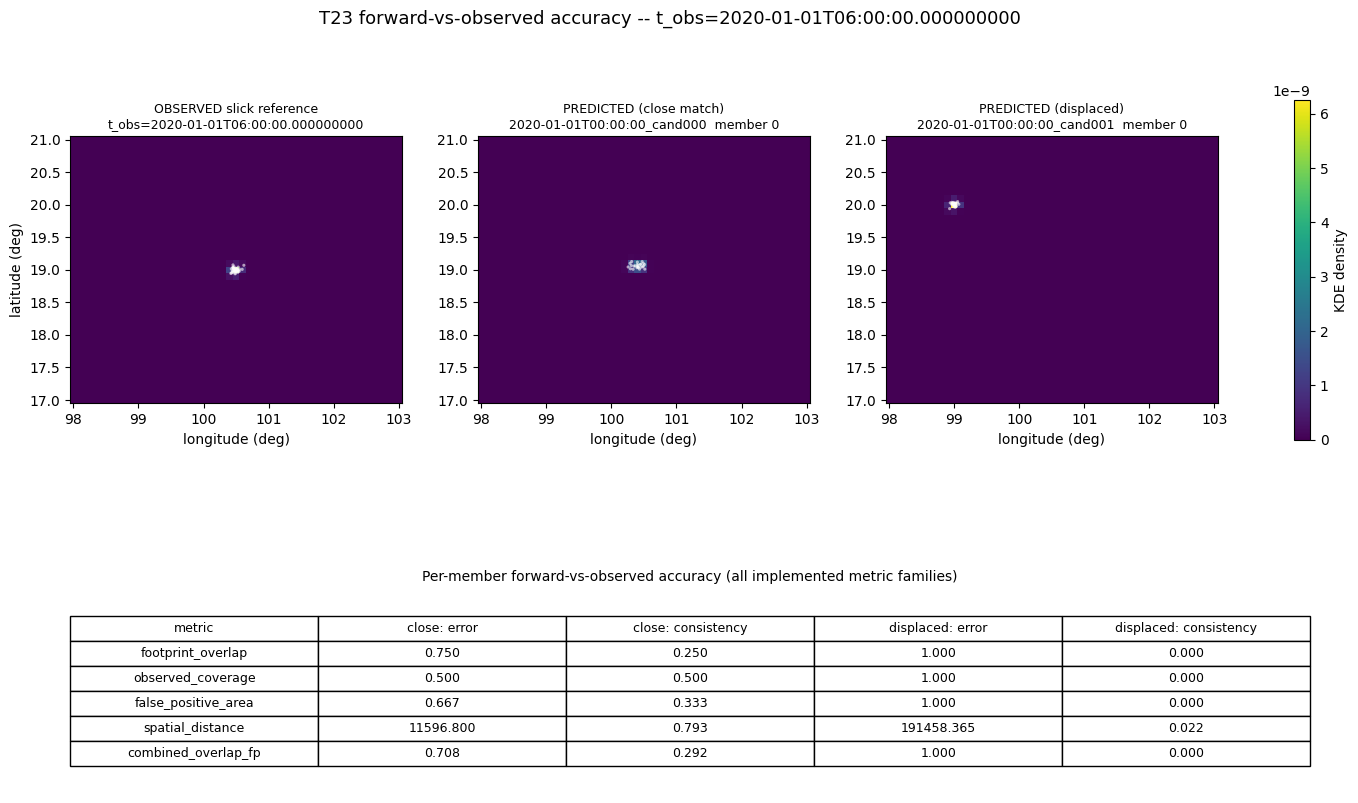

In [5]:
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[3, 1.8], width_ratios=[1, 1, 1, 0.05], hspace=0.55, wspace=0.3)

vmax = max(np.nanmax(observed_fp.density), np.nanmax(predicted_close.density), np.nanmax(predicted_far.density))

panels = [
    (observed_fp, f"OBSERVED slick reference\nt_obs={T_OBS}", (obs_lat, obs_lon)),
    (predicted_close, f"PREDICTED (close match)\n{run_close.candidate_id}  member {run_close.forward_forcing_member_id}", (lat_close, lon_close)),
    (predicted_far, f"PREDICTED (displaced)\n{run_far.candidate_id}  member {run_far.forward_forcing_member_id}", (lat_far, lon_far)),
]
for i, (fp, title, pts) in enumerate(panels):
    ax = fig.add_subplot(gs[0, i])
    mesh = ax.pcolormesh(LON_GRID, LAT_GRID, fp.density, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    ax.scatter(pts[1], pts[0], s=5, c="white", alpha=0.6, edgecolors="none")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("longitude (deg)")
    ax.set_aspect("equal")
    if i == 0:
        ax.set_ylabel("latitude (deg)")
cax = fig.add_subplot(gs[0, 3])
fig.colorbar(mesh, cax=cax, label="KDE density")

ax_table = fig.add_subplot(gs[1, :])
ax_table.axis("off")
ax_table.set_title("Per-member forward-vs-observed accuracy (all implemented metric families)", fontsize=10)
col_labels = ["metric", "close: error", "close: consistency", "displaced: error", "displaced: consistency"]
cell_text = [[m, f"{ec:.3f}", f"{cc:.3f}", f"{ef:.3f}", f"{cf:.3f}"] for m, ec, cc, ef, cf in rows]
table = ax_table.table(cellText=cell_text, colLabels=col_labels, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

fig.suptitle(f"T23 forward-vs-observed accuracy -- t_obs={T_OBS}", fontsize=13)
plt.show()

## Interpretation limits

- This is a **comparison-score** artifact, not a ranking or filtering result. No
  aggregation across forcing members (T24), candidate ranking/filtering (T25), AIS,
  or `c_hat*` is computed here.
- Every metric above is a Phase 2 calibration/configuration choice
  (`README.md` Sec. 22: "the Phase 2 comparison metric is a configurable calibration
  component") -- none is claimed scientifically validated.
- `error`/`consistency` are always complementary and unambiguous in direction: lower
  error = better candidate, higher consistency = better candidate, for every metric
  shown here.
- `footprint_overlap`/`observed_coverage`/`false_positive_area`/`combined_overlap_fp`
  are all area-based (using each footprint's own peak-relative threshold region);
  `spatial_distance` alone is a raw metres value between density-weighted centroids,
  independently converted into a consistency score via an explicit exponential decay
  (`ComparisonConfig.consistency_distance_scale_m`).